In [4]:
import random, numpy as np, torch
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

device: cuda


In [5]:
import torch
import torchvision
import torchvision.transforms as transforms

from torch.utils.data import DataLoader
from torch.utils.data.sampler import SubsetRandomSampler

import numpy as np

In [6]:
batch_size = 64

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))
])

train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

100%|██████████| 170M/170M [34:15<00:00, 82.9kB/s]


In [7]:
num_train = len(train_dataset)
indices = list(range(num_train))

split = int(np.floor(0.2 * num_train))
np.random.shuffle(indices)

train_idx, valid_idx = indices[split:], indices[:split]

train_sampler = SubsetRandomSampler(train_idx)
valid_sampler = SubsetRandomSampler(valid_idx)


In [8]:
batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    sampler=train_sampler
)

valid_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    sampler=valid_sampler
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

In [9]:
print("Train batches:", len(train_loader))
print("Validation batches:", len(valid_loader))
print("Test batches:", len(test_loader))

Train batches: 625
Validation batches: 157
Test batches: 157


In [10]:
classes = train_dataset.classes
print(classes)

['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [11]:
import torch.nn as nn
import torch.nn.functional as F

class CNN1(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(3,32,3,padding=1)
        self.conv2 = nn.Conv2d(32,64,3,padding=1)

        self.pool = nn.MaxPool2d(2,2)

        self.fc1 = nn.Linear(64*8*8,256)
        self.fc2 = nn.Linear(256,10)

    def forward(self,x):

        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))

        x = x.view(x.size(0),-1)

        x = F.relu(self.fc1(x))
        x = self.fc2(x)

        return x

In [12]:
class CNN2(nn.Module):

    def __init__(self):
        super().__init__()

        self.conv = nn.Sequential(

            nn.Conv2d(3,32,3,padding=1),
            nn.ReLU(),
            nn.Conv2d(32,32,3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32,64,3,padding=1),
            nn.ReLU(),
            nn.Conv2d(64,64,3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

        )

        self.fc = nn.Sequential(
            nn.Linear(64*8*8,512),
            nn.ReLU(),
            nn.Linear(512,10)
        )

    def forward(self,x):

        x = self.conv(x)
        x = x.view(x.size(0),-1)
        x = self.fc(x)

        return x

In [13]:
class CNN3(nn.Module):

    def __init__(self):
        super().__init__()

        self.conv = nn.Sequential(

            nn.Conv2d(3,32,3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32,64,3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64,128,3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)

        )

        self.fc = nn.Sequential(

            nn.Linear(128*4*4,256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256,10)

        )

    def forward(self,x):

        x = self.conv(x)
        x = x.view(x.size(0),-1)
        x = self.fc(x)

        return x

In [14]:
from tqdm import tqdm

def train_model(model, epochs=10):

    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    loss_fn = nn.CrossEntropyLoss()

    train_losses = []
    val_losses = []

    train_accs = []
    val_accs = []

    for epoch in range(epochs):

        model.train()

        running_loss = 0
        correct = 0
        total = 0

        loop = tqdm(train_loader)

        for images,labels in loop:

            outputs = model(images)

            loss = loss_fn(outputs,labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

            _,predicted = torch.max(outputs,1)

            total += labels.size(0)
            correct += (predicted==labels).sum().item()

            loop.set_postfix(loss=loss.item())

        train_loss = running_loss/len(train_loader)
        train_acc = 100*correct/total

        train_losses.append(train_loss)
        train_accs.append(train_acc)

        model.eval()

        val_loss = 0
        correct = 0
        total = 0

        with torch.no_grad():

            for images,labels in valid_loader:

                outputs = model(images)
                loss = loss_fn(outputs,labels)

                val_loss += loss.item()

                _,predicted = torch.max(outputs,1)

                total += labels.size(0)
                correct += (predicted==labels).sum().item()

        val_loss /= len(valid_loader)
        val_acc = 100*correct/total

        val_losses.append(val_loss)
        val_accs.append(val_acc)

        print(f"Epoch {epoch+1}")
        print(f"Train Acc {train_acc:.2f}")
        print(f"Val Acc {val_acc:.2f}")

    return train_losses,val_losses,train_accs,val_accs

In [15]:
model1 = CNN1()
model2 = CNN2()
model3 = CNN3()

results1 = train_model(model1)
results2 = train_model(model2)
results3 = train_model(model3)

100%|██████████| 625/625 [00:52<00:00, 11.90it/s, loss=0.919]


Epoch 1
Train Acc 50.57
Val Acc 60.42


100%|██████████| 625/625 [00:55<00:00, 11.16it/s, loss=1.03]


Epoch 2
Train Acc 65.10
Val Acc 66.60


100%|██████████| 625/625 [00:55<00:00, 11.19it/s, loss=0.931]


Epoch 3
Train Acc 71.43
Val Acc 69.38


... (50 outputs left out)

100%|██████████| 625/625 [01:06<00:00,  9.38it/s, loss=0.491]


Epoch 9
Train Acc 82.53
Val Acc 76.33


100%|██████████| 625/625 [01:06<00:00,  9.34it/s, loss=0.49]


Epoch 10
Train Acc 84.31
Val Acc 76.10


In [16]:
import matplotlib.pyplot as plt

def plot_results(results,title):

    train_losses,val_losses,train_accs,val_accs = results

    plt.figure(figsize=(12,5))

    plt.subplot(1,2,1)
    plt.plot(train_losses,label="train")
    plt.plot(val_losses,label="val")
    plt.title(f"{title} Loss")
    plt.legend()

    plt.subplot(1,2,2)
    plt.plot(train_accs,label="train")
    plt.plot(val_accs,label="val")
    plt.title(f"{title} Accuracy")
    plt.legend()

    plt.show()

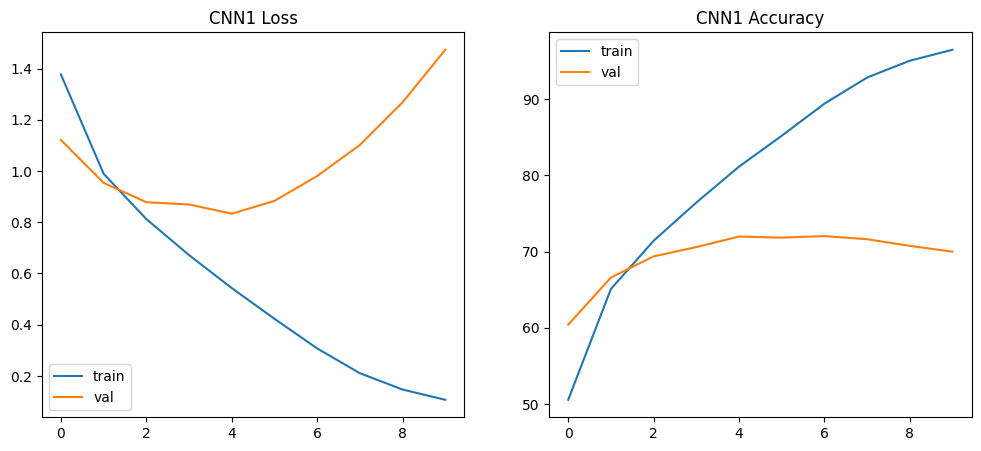

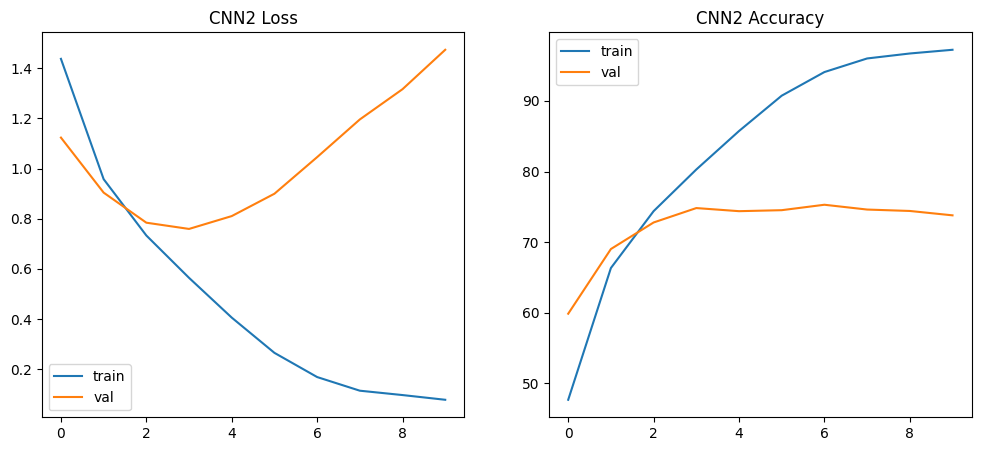

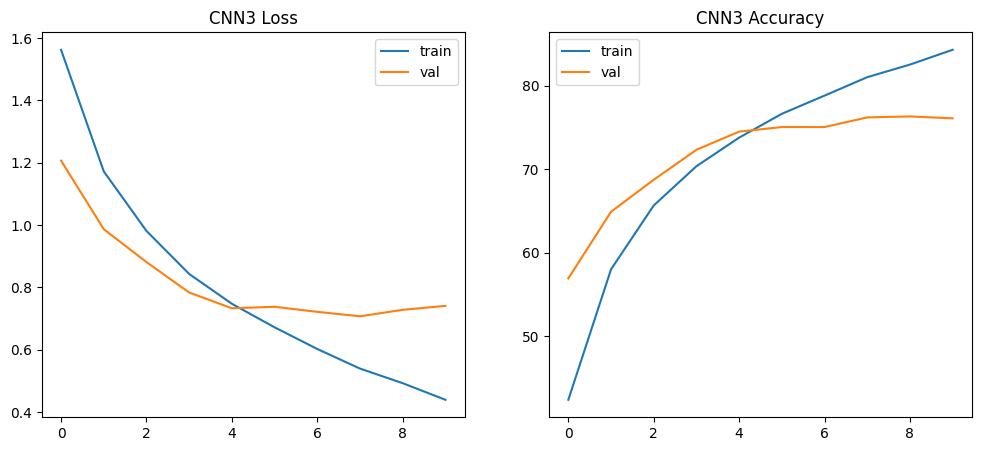

In [17]:
plot_results(results1,"CNN1")
plot_results(results2,"CNN2")
plot_results(results3,"CNN3")

In [ ]:
def test_model(model):

    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():

        for images,labels in test_loader:

            outputs = model(images)

            _,predicted = torch.max(outputs,1)

            total += labels.size(0)
            correct += (predicted==labels).sum().item()

    print("Test accuracy:",100*correct/total)

In [ ]:
test_model(model1)
test_model(model2)
test_model(model3)

Test accuracy: 71.01
Test accuracy: 72.02
Test accuracy: 74.39


In [19]:
from PIL import Image

transform_test = transforms.Compose([
    transforms.Resize((32,32)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))
])

def predict_image(path, model):
    image = Image.open(path).convert("RGB")
    img = transform_test(image).unsqueeze(0)

    model.eval()
    with torch.no_grad():
        output = model(img)
        _, pred = torch.max(output, 1)

    print("Prediction:", classes[pred.item()])

    plt.imshow(image)
    plt.axis("off")
    plt.show()

Prediction: dog


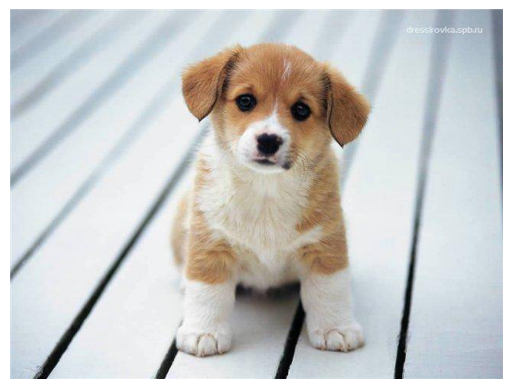

In [30]:
predict_image("dog.jpg", model3)